<a href="https://colab.research.google.com/github/JasmineNasywa/PCVK_Ganjil_2026/blob/main/week7(real)_08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
Nama = 'Jasmine Nasywa N'
NIM = '244107020119'

print(Nama, NIM)

Jasmine Nasywa N 244107020119


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

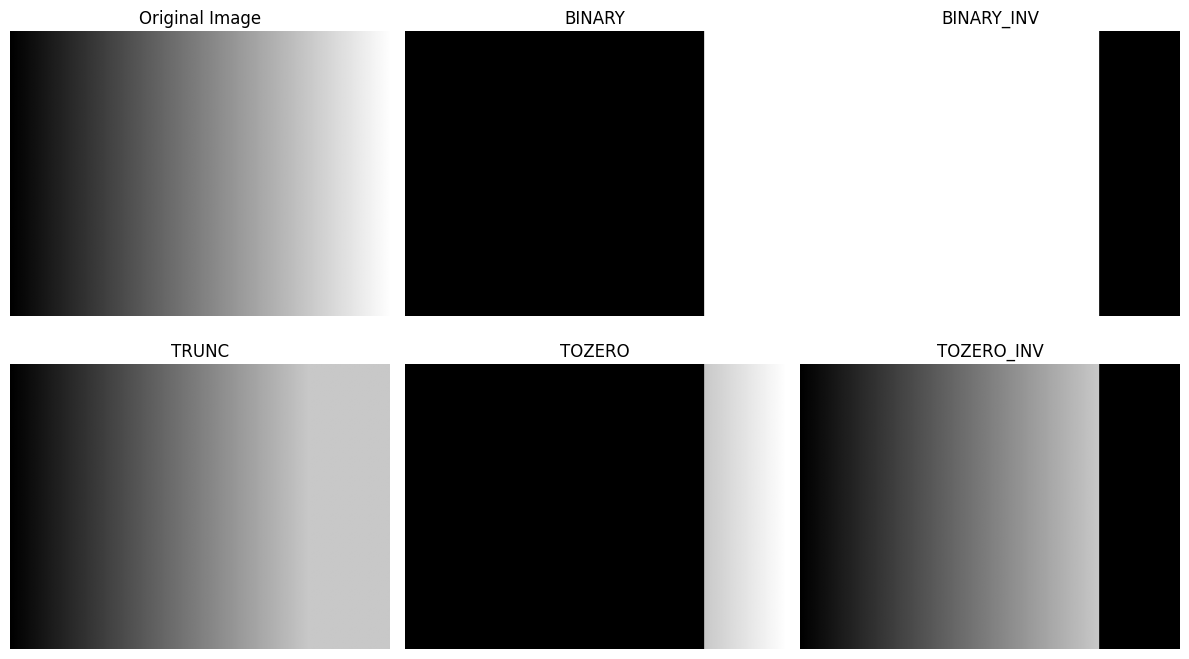

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

img = np.tile(np.linspace(0, 255, 400, dtype=np.uint8), (300, 1))

thresh = 200
max_val = 255

img_binary = img.copy()
img_binary_inv = img.copy()
img_trunc = img.copy()
img_tozero = img.copy()
img_tozero_inv = img.copy()

# --- BINARY ---
img_binary[img > thresh] = max_val
img_binary[img <= thresh] = 0

# --- BINARY_INV ---
img_binary_inv[img > thresh] = 0
img_binary_inv[img <= thresh] = max_val

# --- TRUNC ---
img_trunc[img > thresh] = thresh

# --- TOZERO ---
img_tozero[img <= thresh] = 0

# --- TOZERO_INV ---
img_tozero_inv[img > thresh] = 0

# 3. Plotting/Menampilkan Hasil Menggunakan Matplotlib
titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, img_binary, img_binary_inv, img_trunc, img_tozero, img_tozero_inv]

plt.figure(figsize=(12, 7))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

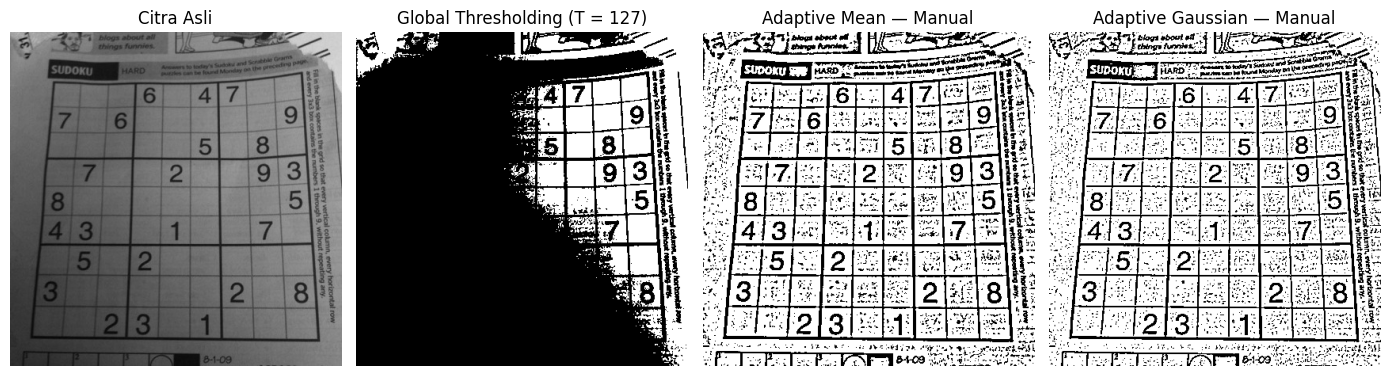

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

filename = '/content/drive/MyDrive/PCVK/sudoku-original.jpg'
img = cv.imread(filename, 0)


# --- Global Threshold (T = 127) ---
global_thresh = 127
max_val = 255
img_global = img.copy()
img_global[img > global_thresh] = max_val
img_global[img <= global_thresh] = 0

def pad_image(image, pad_size):
  return np.pad(image, pad_size, mode='reflect')


# --- Adaptive Mean Manual ---
def adaptive_mean_manual(gray_img, window_size=11, C=2):
  h, w = gray_img.shape
  pad = window_size // 2
  padded = pad_image(gray_img, pad)
  out = np.zeros_like(gray_img)

  # Menggunakan integral image / perulangan efisien untuk mean lokal
  for y in range(h):
    for x in range(w):
      # Ambil window/jendela tetangga ukuran 11x11
      window = padded[y : y + window_size, x : x + window_size]
      local_mean = np.mean(window)

      # Threshold lokal = mean - C
      thresh_val = local_mean - C

      # Binarisasi piksel
      if gray_img[y, x] > thresh_val:
        out[y, x] = 255
      else:
        out[y, x] = 0
  return out


# --- Adaptive Gaussian Manual ---
def create_gaussian_kernel(size=11, sigma=2):
  pad = size // 2
  ax = np.arange(-pad, pad + 1)
  xx, yy = np.meshgrid(ax, ax)
  kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
  return kernel / np.sum(kernel)


def adaptive_gaussian_manual(gray_img, window_size=11, sigma=2, C=2):
  h, w = gray_img.shape
  pad = window_size // 2
  padded = pad_image(gray_img, pad)
  kernel = create_gaussian_kernel(window_size, sigma)
  out = np.zeros_like(gray_img)

  for y in range(h):
    for x in range(w):
      window = padded[y : y + window_size, x : x + window_size]
      # Hitung weighted sum menggunakan kernel Gaussian
      local_gaussian_mean = np.sum(window * kernel)

      thresh_val = local_gaussian_mean - C

      if gray_img[y, x] > thresh_val:
        out[y, x] = 255
      else:
        out[y, x] = 0
  return out




img_mean = adaptive_mean_manual(img, window_size=11, C=2)
img_gauss = adaptive_gaussian_manual(img, window_size=11, sigma=2, C=2)

titles = [
    'Citra Asli',
    'Global Thresholding (T = 127)',
    'Adaptive Mean — Manual',
    'Adaptive Gaussian — Manual',
]
images = [img, img_global, img_mean, img_gauss]

plt.figure(figsize=(14, 5))
for i in range(4):
  plt.subplot(1, 4, i + 1)
  plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
  plt.title(titles[i])
  plt.axis('off')

plt.tight_layout()
plt.show()

Threshold Otsu Optimal: 114


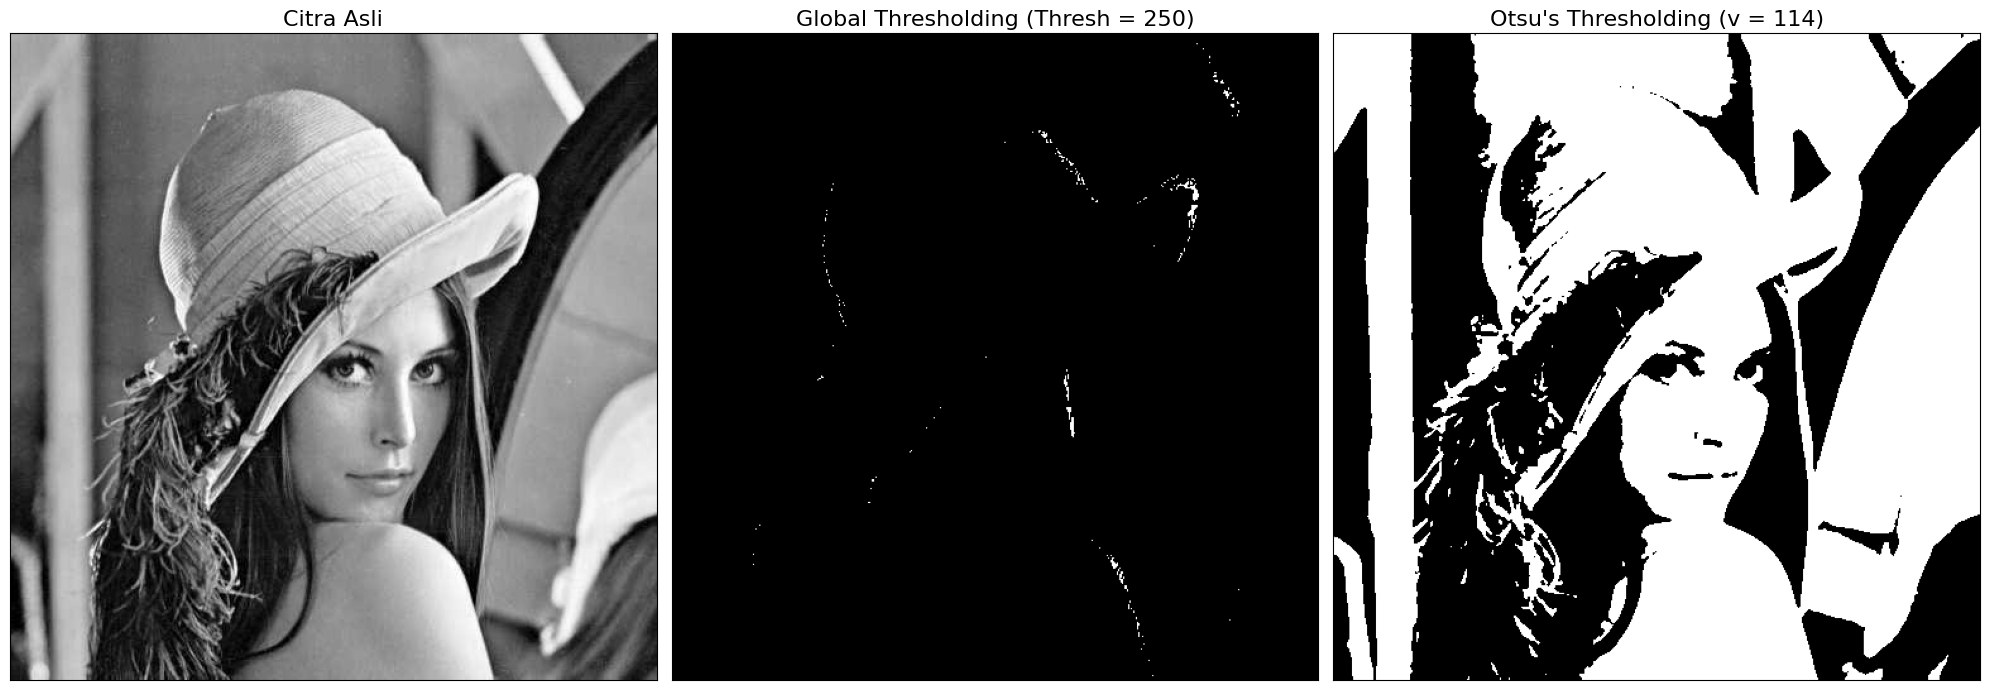

In [ ]:
filename = '/content/drive/MyDrive/PCVK/lena.jpg'
img = cv.imread(filename, 0)


if img is None:
    print(f"Error: Gambar tidak ditemukan di path '{filename}'")
else:
    blur = cv.GaussianBlur(img, (5, 5), 0)


    thresh_manual = 250

    # Otsu (manual, tanpa cv.threshold())
    def otsu(gray):
      pixel_number = gray.shape[0] * gray.shape[1]
      mean_weight = 1.0 / pixel_number
      his, bins = np.histogram(gray, bins=np.arange(0, 257))

      final_thresh = -1
      final_value = -1.0
      intensity_arr = np.arange(256)

      for t in range(1, 256):
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])

        if pcb == 0 or pcf == 0:
          continue

        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)

        value = Wb * Wf * ((mub - muf) ** 2)

        if value > final_value:
          final_thresh = t
          final_value = value


      final_img_otsu = gray.copy()
      final_img_otsu[gray >= final_thresh] = 255
      final_img_otsu[gray < final_thresh] = 0

      return final_img_otsu, final_thresh

    otsu_biner, otsu_thresh_val = otsu(blur)
    print(f'Threshold Otsu Optimal: {otsu_thresh_val}')



    thl_global = img.copy()
    thl_global[img > thresh_manual] = 255
    thl_global[img <= thresh_manual] = 0

    titles = [
        'Citra Asli',
        f'Global Thresholding (Thresh = {thresh_manual})',
        f"Otsu's Thresholding (v = {otsu_thresh_val})",
    ]
    citra3 = [img, thl_global, otsu_biner]

    plt.figure(figsize=(20, 15))
    for i in range(len(citra3)):
      plt.subplot(1, 3, i + 1)
      plt.imshow(citra3[i], cmap='gray', vmin=0, vmax=255)
      plt.title(titles[i], fontsize=16)
      plt.xticks([])
      plt.yticks([])

    plt.tight_layout()
    plt.show()

Hal ini terjadi karena nilai ambang batas (Thresh) yang digunakan (misal 127) berada di atas seluruh atau sebagian besar rentang intensitas piksel dari gambar citra yang diuji (atau gambar tersebut memiliki karakteristik pencahayaan/kontras yang gelap/rendah).

Threshold Otsu Optimal: 114


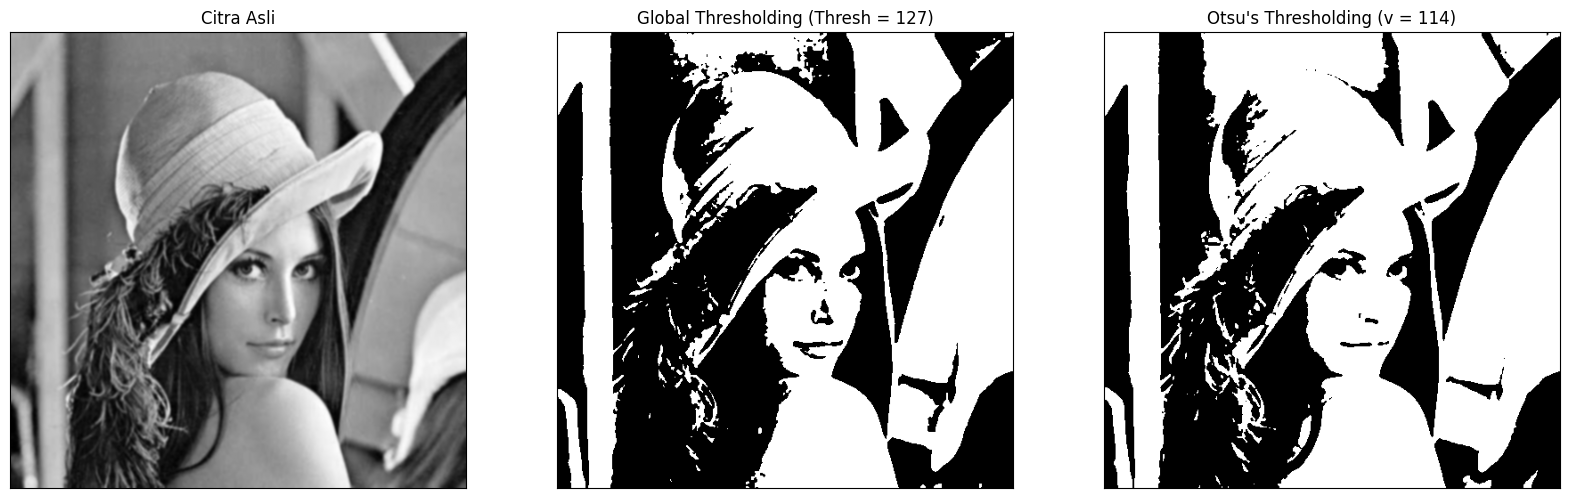

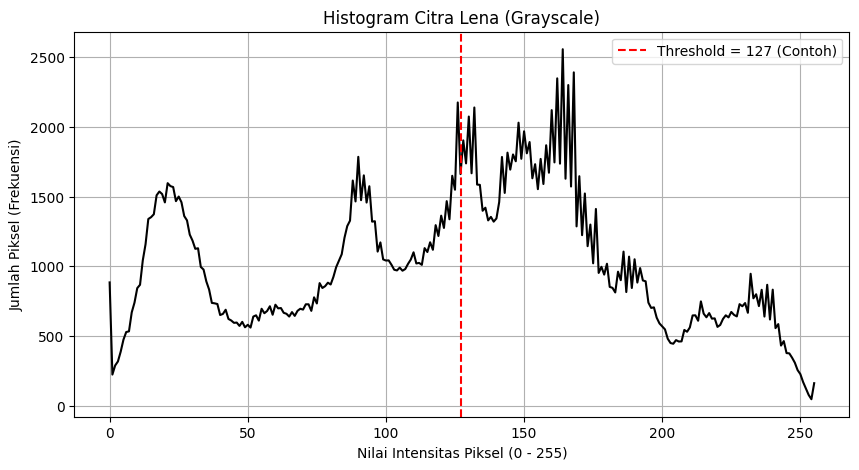

In [ ]:

filename = '/content/drive/MyDrive/PCVK/lena.jpg'
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127


def otsu(gray):
  pixel_number = gray.shape[0] * gray.shape[1]
  mean_weight = 1.0 / pixel_number
  his, bins = np.histogram(gray, bins=np.arange(0, 257))

  final_thresh = -1
  final_value = -1.0
  intensity_arr = np.arange(256)

  for t in range(1, 256):
    pcb = np.sum(his[:t])
    pcf = np.sum(his[t:])


    if pcb == 0 or pcf == 0:
      continue

    Wb = pcb * mean_weight
    Wf = pcf * mean_weight

    mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
    muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)

    value = Wb * Wf * ((mub - muf) ** 2)

    if value > final_value:
      final_thresh = t
      final_value = value

  final_img = gray.copy()
  print('Threshold Otsu Optimal:', final_thresh)

  final_img[gray >= final_thresh] = 255
  final_img[gray < final_thresh] = 0

  return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = 'Otsu\'s Thresholding (v = ' + str(otsu_thresh) + ')'

ret, thl = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

titles = [
    'Citra Asli',
    'Global Thresholding (Thresh = ' + str(thresh) + ')',
    x,
]
citra3 = [blur, thl, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
  plt.subplot(1, 3, i + 1)
  plt.imshow(citra3[i], cmap='gray')
  plt.title(titles[i])
  plt.xticks([])
  plt.yticks([])

plt.show()


hist = cv.calcHist([img], [0], None, [256], [0, 256])

plt.figure(figsize=(10, 5))
plt.plot(hist, color='black')
plt.title('Histogram Citra Lena (Grayscale)')
plt.xlabel('Nilai Intensitas Piksel (0 - 255)')
plt.ylabel('Jumlah Piksel (Frekuensi)')
plt.axvline(
    x=127, color='red', linestyle='--', label='Threshold = 127 (Contoh)'
)
plt.legend()
plt.grid(True)
plt.show()

Threshold Otsu Optimal: 104


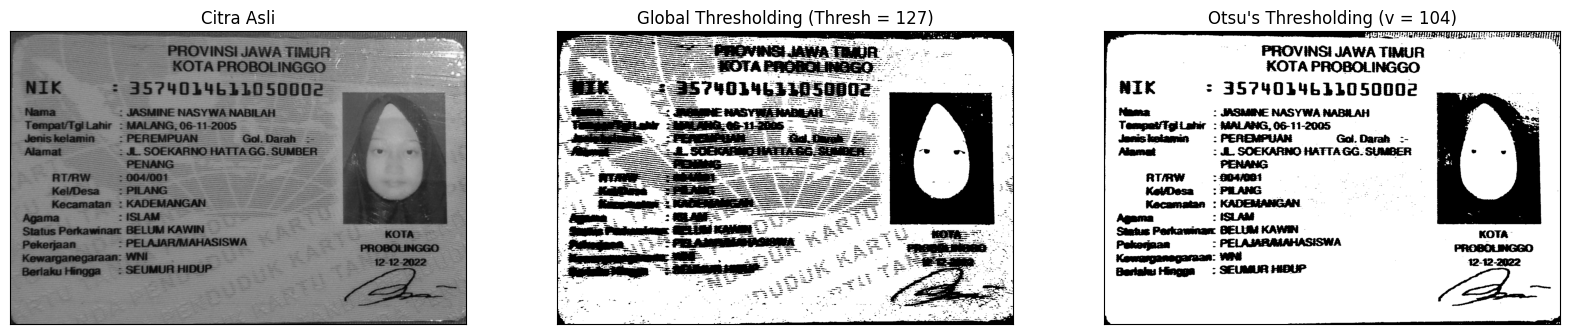

In [ ]:
filename = '/content/drive/MyDrive/PCVK/KTP1B.jpeg'
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127


def otsu(gray):
  pixel_number = gray.shape[0] * gray.shape[1]
  mean_weight = 1.0 / pixel_number
  his, bins = np.histogram(gray, bins=np.arange(0, 257))

  final_thresh = -1
  final_value = -1.0
  intensity_arr = np.arange(256)

  for t in range(1, 256):
    pcb = np.sum(his[:t])
    pcf = np.sum(his[t:])


    if pcb == 0 or pcf == 0:
      continue

    Wb = pcb * mean_weight
    Wf = pcf * mean_weight

    mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
    muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)

    value = Wb * Wf * ((mub - muf) ** 2)

    if value > final_value:
      final_thresh = t
      final_value = value

  final_img = gray.copy()
  print('Threshold Otsu Optimal:', final_thresh)

  final_img[gray >= final_thresh] = 255
  final_img[gray < final_thresh] = 0

  return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = 'Otsu\'s Thresholding (v = ' + str(otsu_thresh) + ')'

ret, thl = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

titles = [
    'Citra Asli',
    'Global Thresholding (Thresh = ' + str(thresh) + ')',
    x,
]
citra3 = [blur, thl, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
  plt.subplot(1, 3, i + 1)
  plt.imshow(citra3[i], cmap='gray')
  plt.title(titles[i])
  plt.xticks([])
  plt.yticks([])

plt.show()

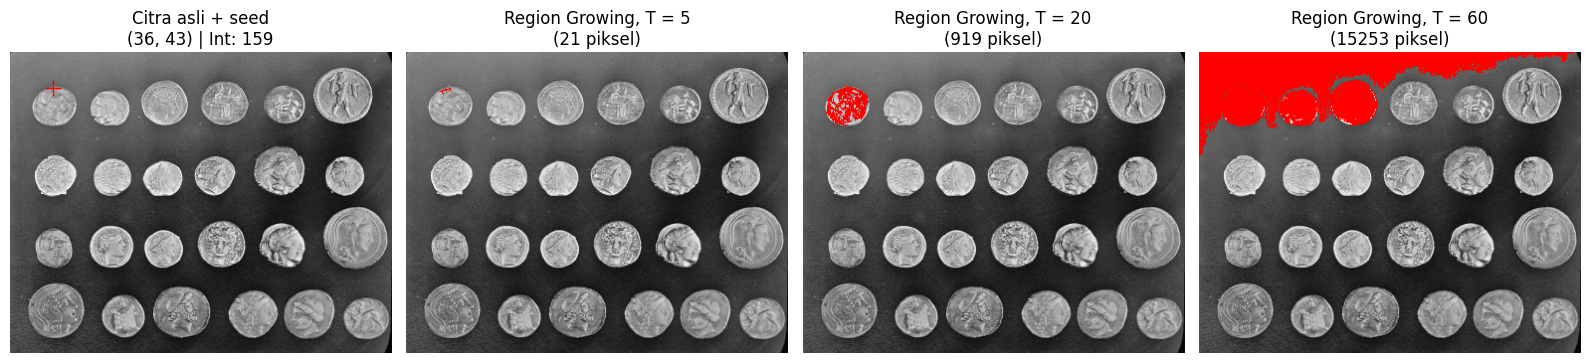

In [ ]:
from skimage import data
from skimage.segmentation import flood

gray = data.coins()

seed_point = (36, 43)
tolerances = [5, 20, 60]

plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(gray, cmap='gray')
plt.plot(seed_point[1], seed_point[0], 'r+', markersize=12)
intensitas_seed = gray[seed_point]
plt.title(
    f'Citra asli + seed\n({seed_point[0]}, {seed_point[1]}) | Int: {intensitas_seed}'
)
plt.axis('off')

for i, t in enumerate(tolerances):
  region = flood(gray, seed_point=seed_point, tolerance=t, connectivity=1)

  pixel_count = np.sum(region)

  overlay = np.stack([gray, gray, gray], axis=-1)
  overlay[region] = [255, 0, 0]

  plt.subplot(1, 4, i + 2)
  plt.imshow(overlay)
  plt.title(f'Region Growing, T = {t}\n({pixel_count} piksel)')
  plt.axis('off')

plt.tight_layout()
plt.show()

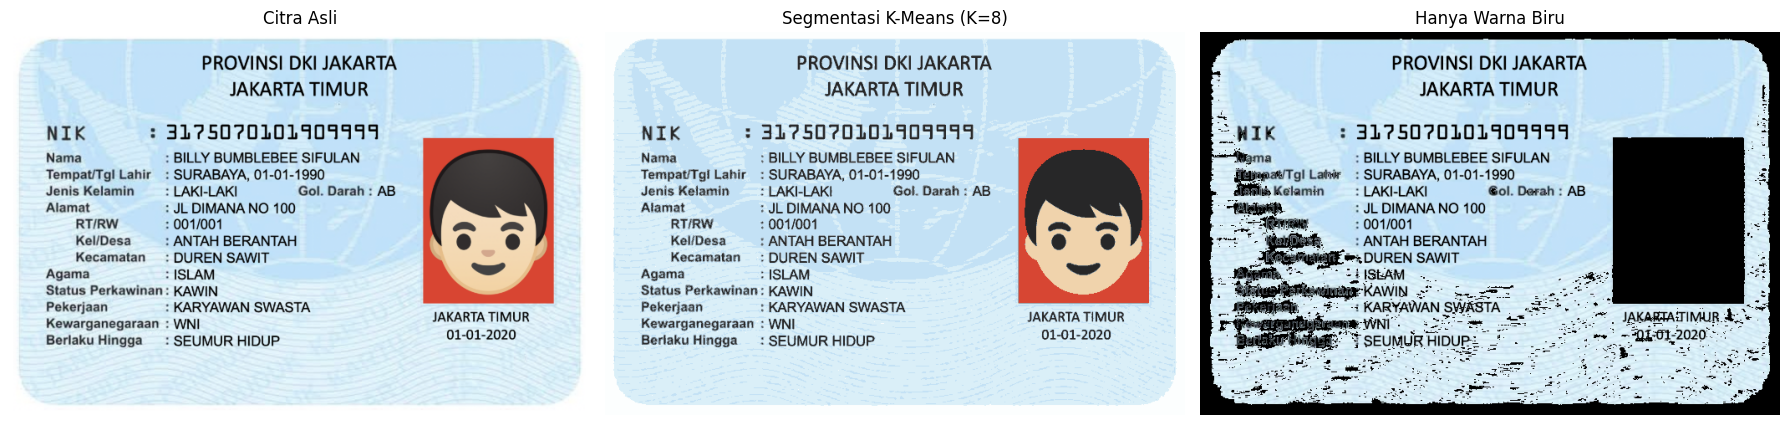

In [ ]:
filename = '/content/drive/MyDrive/PCVK/ktp_fulan.jpg'
img_bgr = cv.imread(filename)

img_hsv = cv.cvtColor(img_bgr, cv.COLOR_BGR2HSV)
H = img_hsv[:, :, 0]
S = img_hsv[:, :, 1]
V = img_hsv[:, :, 2]

kelompok_biru = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)

img_biru_saja = img_bgr.copy()
img_biru_saja[~kelompok_biru] = [0, 0, 0]

pixel_values = img_bgr.reshape((-1, 3))
pixel_values = np.float32(pixel_values)
criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 100, 0.2)
k = 8
_, labels, centers = cv.kmeans(
    pixel_values, k, None, criteria, 10, cv.KMEANS_RANDOM_CENTERS
)
centers = np.uint8(centers)
segmented_image = centers[labels.flatten()].reshape(img_bgr.shape)

img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
segmented_rgb = cv.cvtColor(segmented_image, cv.COLOR_BGR2RGB)
img_biru_rgb = cv.cvtColor(img_biru_saja, cv.COLOR_BGR2RGB)

titles = ['Citra Asli', 'Segmentasi K-Means (K=8)', 'Hanya Warna Biru']
images = [img_rgb, segmented_rgb, img_biru_rgb]

plt.figure(figsize=(18, 6))
for i in range(3):
  plt.subplot(1, 3, i + 1)
  plt.imshow(images[i])
  plt.title(titles[i])
  plt.axis('off')

plt.tight_layout()
plt.show()

# TUGAS KELOMPOK

In [ ]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


In [ ]:
import os
import cv2 as cv
import numpy as np
import pandas as pd
import pytesseract
import re
import difflib
import matplotlib.pyplot as plt
from pytesseract import Output

imgktp = '/content/drive/MyDrive/PCVK/KTP1B.jpeg'

# Cek file ada
if not os.path.exists(imgktp):
    folder = os.path.dirname(imgktp)
    print("File tidak ditemukan:", imgktp)
    print("Isi folder:", os.listdir(folder) if os.path.exists(folder) else "(folder tidak ada)")
    raise FileNotFoundError("Cek nama file/folder di atas.")

# Cek gambar bisa dibaca
test = cv.imdecode(np.fromfile(imgktp, dtype=np.uint8), cv.IMREAD_COLOR)
if test is None:
    raise ValueError("File ada tapi gagal dibaca. Pastikan formatnya JPG/PNG valid.")
print("File dipakai:", imgktp, "| ukuran:", test.shape)
# klo mau upload lokal
# uploaded = files.upload()
# IMAGE_PATH = list(uploaded.keys())[0]
# print("File dipakai:", IMAGE_PATH)

LANG = "ind"
CONFIG = "--psm 6"
CONF_THRESHOLD = 60

File dipakai: /content/drive/MyDrive/PCVK/KTP1B.jpeg | ukuran: (1027, 1600, 3)


## 1. Persiapan Tiga Citra
Ketiga citra memakai ukuran yang sama. Untuk Otsu dan Adaptive, citra diubah ke grayscale terlebih dahulu.

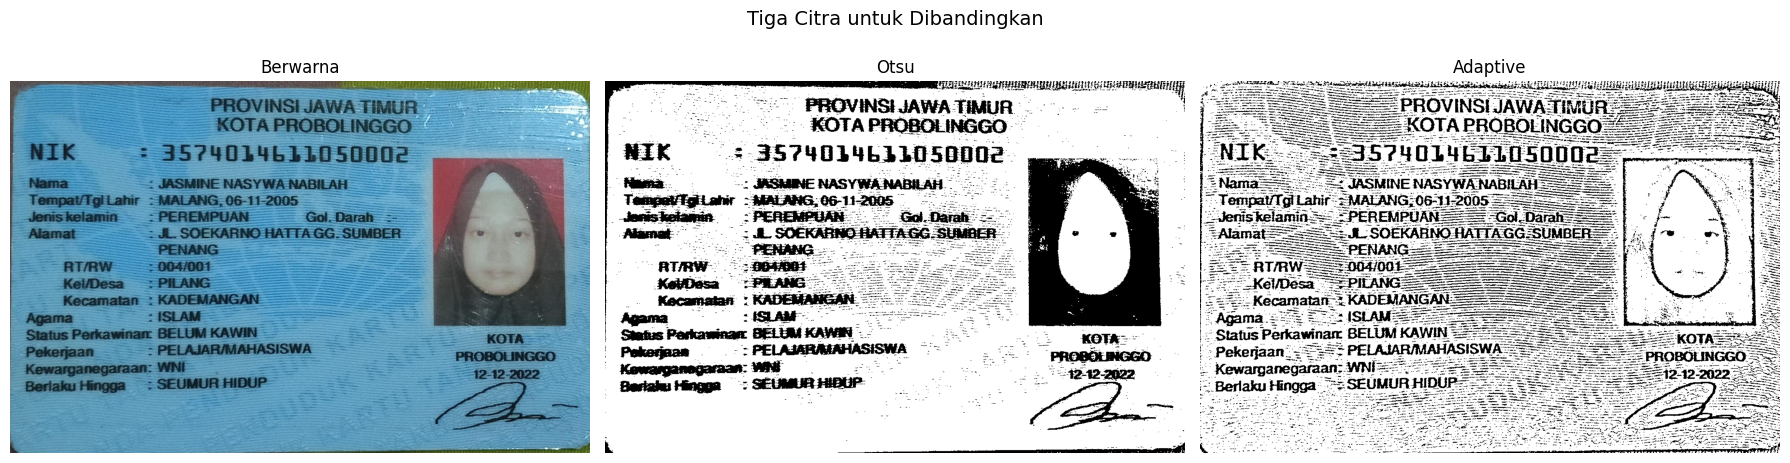

In [ ]:
# Baca citra & samakan ukuran lebar 1200 px, rasio sama
img_bgr = cv.imdecode(np.fromfile(imgktp, dtype=np.uint8), cv.IMREAD_COLOR)
if img_bgr is None:
    raise ValueError(f"Gambar gagal dibaca dari: {imgktp}")

h, w = img_bgr.shape[:2]
new_w = 1200
new_h = int(h * new_w / w)
img_bgr = cv.resize(img_bgr, (new_w, new_h), interpolation=cv.INTER_CUBIC)

# 1) Citra berwarna asli
img_color = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

# Grayscale
gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

# 2) Otsu
_, img_otsu = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

# 3) Adaptive Thresh
img_adaptive = cv.adaptiveThreshold(
    gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv.THRESH_BINARY, 31, 10
)

images = {
    "Berwarna": img_color,
    "Otsu": img_otsu,
    "Adaptive": img_adaptive,
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, im) in zip(axes, images.items()):
    ax.imshow(im, cmap="gray" if im.ndim == 2 else None)
    ax.set_title(name)
    ax.axis("off")
plt.suptitle("Tiga Citra untuk Dibandingkan", fontsize=14)
plt.tight_layout()
plt.show()

## 2. Pembacaan Teks dengan image_to_string()
Bahasa Indonesia (ind) dan --psm 6 dipakai sama untuk ketiga citra.

In [ ]:
ocr_text = {}
for name, im in images.items():
    ocr_text[name] = pytesseract.image_to_string(im, lang=LANG, config=CONFIG)

for name, txt in ocr_text.items():
    print(f"========== {name.upper()} ==========")
    print(txt.strip())
    print()

========== BERWARNA ==========
Oa  AROVWSI JAWA TIMUR |
NIK: 357Y0OL4LI1050000 3
- 2 2. na

— TempatiTgiLahir : MALANG:06-112005 ..
PA T—— PA , ji 2

========== OTSU ==========
., PN Ab na Sea aa pu
Je TE PROVINSIJAWA TIMUR. — |
Ak KOTA PROBOLINGGO - :
NIK: 3S74014621050000 sa
TempatTgiLahir : MALANG,06-11-2005 f “
| Status Perkawinan BELUMKAYAN -————”.i- Kota
| Pasal garam: ME Sp tpapap

========== ADAPTIVE ==========
Pe 3 PROVINSIJAWATIMUR ai
( KOTAPROBOLINGGO 5
NIK 55235 PYO1Y6IL OSN Oo Eh
“Tempat/IgiLahir #MALANG:06111-2005 F2 2-5.) ' 7 Kuda
HJeriskelamin ss: PEREMPUAN “Gol.Daah-2 5 "oo «ji
#Alamat 255 JL SOEKARNO HATTAGG-SUMBER “|, fe. «io Jul
Me NN Ss an EN Aa Sian JA AN AN RPL NG PRE ah Ma ea



## 3. Area Teks Terdeteksi dengan image_to_data()
Kotak hijau hanya ditampilkan untuk kata dengan confidence > 60.

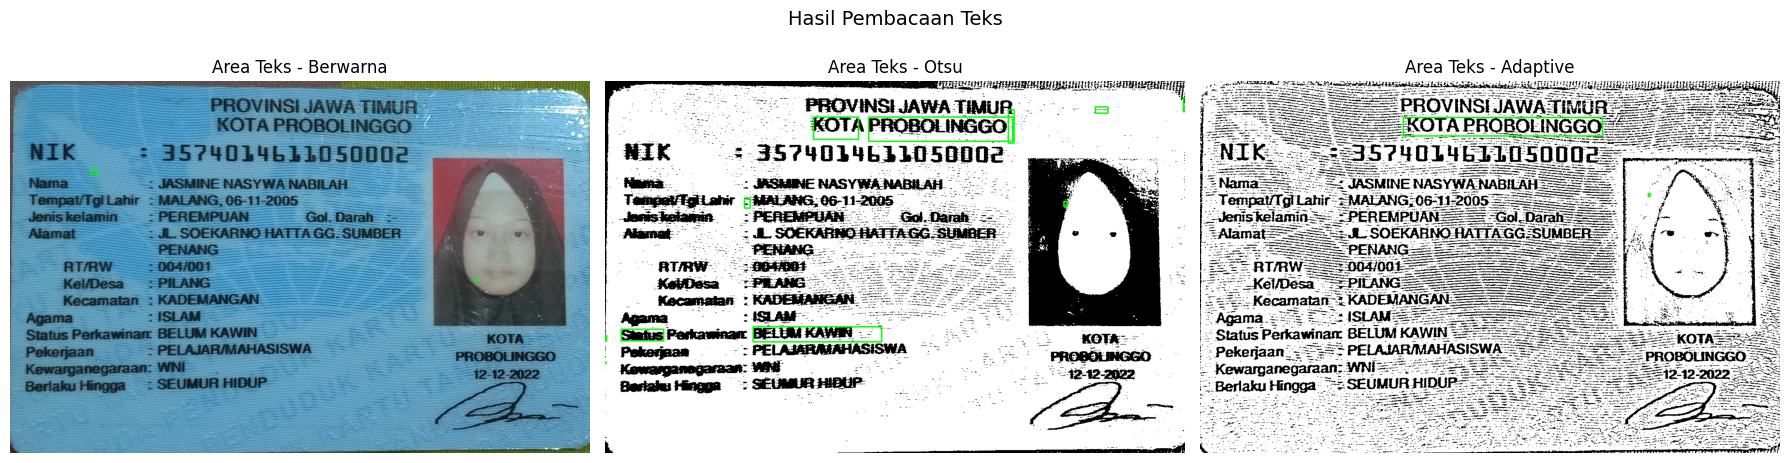

In [ ]:
ocr_data = {}
for name, im in images.items():
    d = pytesseract.image_to_data(im, lang=LANG, config=CONFIG, output_type=Output.DATAFRAME)
    d = d.dropna(subset=["text"])
    d = d[d["text"].astype(str).str.strip() != ""]
    d = d[d["conf"] >= 0]
    ocr_data[name] = d

titles = {
    "Berwarna": "Area Teks - Berwarna",
    "Otsu": "Area Teks - Otsu",
    "Adaptive": "Area Teks - Adaptive",
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, im) in zip(axes, images.items()):
    vis = im.copy() if im.ndim == 3 else cv.cvtColor(im, cv.COLOR_GRAY2RGB)
    d = ocr_data[name]
    for _, r in d[d["conf"] > CONF_THRESHOLD].iterrows():
        x, y, bw, bh = int(r.left), int(r.top), int(r.width), int(r.height)
        cv.rectangle(vis, (x, y), (x + bw, y + bh), (0, 255, 0), 2)
    ax.imshow(vis)
    ax.set_title(titles[name])
    ax.axis("off")
plt.suptitle("Hasil Pembacaan Teks", fontsize=14)
plt.tight_layout()
plt.show()

## 4. Perbandingan Hasil Pembacaan

In [ ]:

ground_truth = [
    "3574014611050002",     # 1  NIK
    "JASMINE NASYWA NABILAH",  # 2  Nama
    "MALANG",               # 3  Tempat lahir
    "06-11-2005",           # 4  Tanggal lahir
    "PEREMPUAN",            # 5  Jenis kelamin
    "JL SOEKARNO HATTA GG.SUMBER PENANG",     # 6  Alamat
    "KADEMANGAN",           # 7  Kecamatan
    "ISLAM",                # 8  Agama
    "BELUM KAWIN",          # 9  Status perkawinan
    "PELAJAR/MAHASISWA",    # 10 Pekerjaan
]

def normalize(s):
    """Huruf besar/kecil dan spasi di awal/akhir/dalam diabaikan."""
    return re.sub(r"\s+", "", str(s).lower())

def best_match_line(item, text):
    """Ambil potongan teks hasil OCR yang paling mirip dengan item (untuk ditampilkan di tabel)."""
    lines = [l.strip() for l in text.splitlines() if l.strip()]
    cands = []
    for l in lines:
        cands.append(l)
        if ":" in l:
            cands.append(l.split(":", 1)[1].strip())
    if not cands:
        return "-"
    norm_map = {normalize(c): c for c in cands}
    m = difflib.get_close_matches(normalize(item), list(norm_map.keys()), n=1, cutoff=0.0)
    return norm_map[m[0]] if m else "-"

def is_match(item, text):
    return normalize(item) in normalize(text)

rows = []
hit = {"Berwarna": 0, "Otsu": 0, "Adaptive": 0}
for i, item in enumerate(ground_truth, 1):
    row = {"No.": i, "Teks sebenarnya": item}
    for name, label in [("Berwarna", "OCR citra berwarna"),
                        ("Otsu", "OCR Otsu"),
                        ("Adaptive", "OCR Adaptive")]:
        ok = is_match(item, ocr_text[name])
        hit[name] += int(ok)
        row[label] = best_match_line(item, ocr_text[name]) if not ok else item
        row[label] = ("✔ " if ok else "✘ ") + row[label]
    rows.append(row)

df_compare = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", None)
display(df_compare)

,No.,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
0,1,3574014611050002,✘ 357Y0OL4LI1050000 3,✘ 3S74014621050000 sa,✘ 06111-2005 F2 2-5.) ' 7 Kuda
1,2,JASMINE NASYWA NABILAH,✘ Oa AROVWSI JAWA TIMUR |,✘ ME Sp tpapap,✘ Me NN Ss an EN Aa Sian JA AN AN RPL NG PRE ah Ma ea
2,3,MALANG,✔ MALANG,✔ MALANG,✔ MALANG
3,4,06-11-2005,✘ MALANG:06-112005 ..,✔ 06-11-2005,✘ 06111-2005 F2 2-5.) ' 7 Kuda
4,5,PEREMPUAN,✘ — TempatiTgiLahir : MALANG:06-112005 ..,"✘ ., PN Ab na Sea aa pu",✔ PEREMPUAN
5,6,JL SOEKARNO HATTA GG.SUMBER PENANG,✘ Oa AROVWSI JAWA TIMUR |,✘ | Pasal garam: ME Sp tpapap,"✘ #Alamat 255 JL SOEKARNO HATTAGG-SUMBER “|, fe. «io Jul"
6,7,KADEMANGAN,✘ MALANG:06-112005 ..,✘ ME Sp tpapap,"✘ PEREMPUAN “Gol.Daah-2 5 ""oo «ji"
7,8,ISLAM,✘ — TempatiTgiLahir : MALANG:06-112005 ..,✘ | Pasal garam: ME Sp tpapap,✘ Pe 3 PROVINSIJAWATIMUR ai
8,9,BELUM KAWIN,✘ — TempatiTgiLahir : MALANG:06-112005 ..,✘ | Status Perkawinan BELUMKAYAN -————”.i- Kota,✘ ( KOTAPROBOLINGGO 5
9,10,PELAJAR/MAHASISWA,✘ Oa AROVWSI JAWA TIMUR |,"✘ ., PN Ab na Sea aa pu",✘ Pe 3 PROVINSIJAWATIMUR ai


## 5. Persentase Kecocokan & Rata-rata Confidence
Item dinyatakan cocok jika seluruh huruf/angka sama (tanpa membedakan huruf besar-kecil dan spasi awal/akhir).

,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,1 / 10,10.0,26.74
1,Segmentasi Otsu,2 / 10,20.0,32.05
2,Segmentasi Adaptive,2 / 10,20.0,19.62


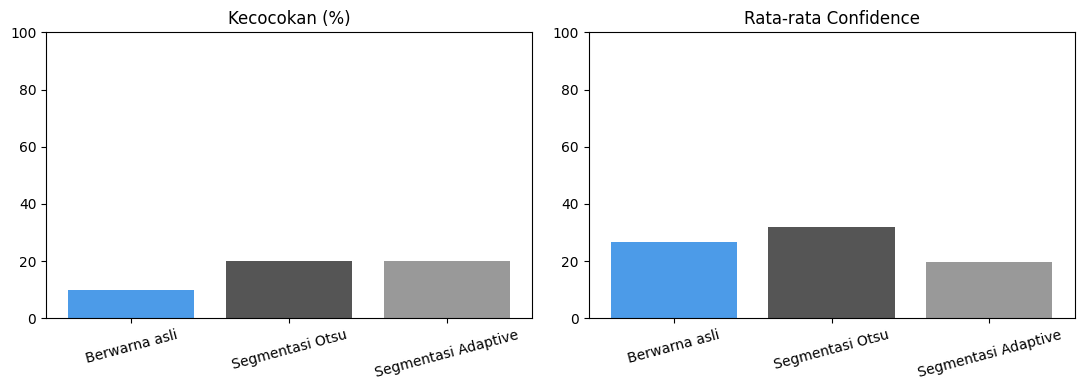

In [ ]:
summary = []
for name, label in [("Berwarna", "Berwarna asli"),
                    ("Otsu", "Segmentasi Otsu"),
                    ("Adaptive", "Segmentasi Adaptive")]:
    d = ocr_data[name]
    summary.append({
        "Citra masukan OCR": label,
        "Item terbaca tepat": f"{hit[name]} / 10",
        "Kecocokan (%)": round(hit[name] / 10 * 100, 2),
        "Rata-rata confidence": round(d["conf"].mean(), 2),
    })

df_summary = pd.DataFrame(summary)
display(df_summary)

# Grafik pendukung analisis
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(df_summary["Citra masukan OCR"], df_summary["Kecocokan (%)"], color=["#4c9be8", "#555", "#999"])
ax[0].set_title("Kecocokan (%)"); ax[0].set_ylim(0, 100)
ax[1].bar(df_summary["Citra masukan OCR"], df_summary["Rata-rata confidence"], color=["#4c9be8", "#555", "#999"])
ax[1].set_title("Rata-rata Confidence"); ax[1].set_ylim(0, 100)
for a in ax:
    a.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## 6. Contoh Hasil Pembacaan Citra Berwarna

In [ ]:
print("========== BERWARNA ==========")
print(ocr_text["Berwarna"].strip())

========== BERWARNA ==========
Oa  AROVWSI JAWA TIMUR |
NIK: 357Y0OL4LI1050000 3
- 2 2. na

— TempatiTgiLahir : MALANG:06-112005 ..
PA T—— PA , ji 2


## 7. Pertanyaan Analisis

**1. Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari tabel.**  
Citra segmentasi otsu paling tepat, dengan kecocokan 20% dan rata-rata confidence 32.05, lebih tinggi dibanding citra lainnya (lihat tabel ringkasan).

**2. Sebutkan minimal dua kesalahan pembacaan .**  
- angka nik salah terbaca menjadi huruf
- nama dan beberapa teks terbaca salah dan ngawur

**3. Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan berdasarkan hasil percobaan.**  
Tidak selalu. Pada percobaan ini, otsu dan dan adaptive sedikit lebih baik daripada citra berwarna Otsu memakai satu ambang global sehingga rentan pada pencahayaan tidak merata dan latar bermotif, sedangkan Adaptive memakai ambang lokal namun bisa menimbulkan noise pada area latar.

**4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?**  
Latar berwarna mengurangi kontras antara teks dan latar sehingga huruf mudah tertukar atau tidak terdeteksi. Setelah segmentasi, latar menjadi putih polos dan teks hitam sehingga teks lebih mudah terbaca.

**5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?**  
Pada kasus ini, termasuk tertinggi bersama dengan adaptive dibandingkan dengan citra berwarna. Tapi confidence hanyalah keyakinan internal Tesseract, bukan jaminan kebenaran. teks yang salah baca tetap bisa memiliki confidence tinggi, dan citra yang banyak kehilangan kata bisa memiliki rata-rata confidence tinggi karena hanya kata yang mudah yang tersisa.